In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from datetime import datetime

In [3]:
# filepaths
meb_file = r'data\MEBCro_for.nc'
fsm_file = r'data\FSM_all_corr.nc'

# reading both simulations
meb_all = xr.open_dataset(meb_file)
fsm_all = xr.open_dataset(fsm_file)

# consistent periods
time = slice(str(meb_all['time'][0].values), str(meb_all['time'][-1].values))
fsm_all = fsm_all.sel(time=time)
fsm_all = fsm_all.where(fsm_all != -9999, np.nan)

# saving canopy etc. elsewhere
canopy = fsm_all[['lai', 'hcan', 'dem', 'aspect']].copy()

# masking non-forests
fsm_all = fsm_all.where(
    (fsm_all['swet_for'] != -9999.) &
    (~np.isnan(fsm_all['swet_for'])))
meb_all = meb_all.where(
    (fsm_all['swet_for'] != -9999.) & 
    (~np.isnan(fsm_all['swet_for'])))

# masking snow-free
meb_snow = meb_all.where(
    (meb_all['swet_all'] > 10) &
    (fsm_all['swet_all'] > 10))
fsm_snow = fsm_all.where(
    (fsm_all['swet_all'] > 10) &
    (meb_all['swet_all'] > 10))

In [4]:
class_low = [0.0, 3.5]
class_high = [2, 8]
fsm_classes = {}
meb_classes = {}

for i in range(len(class_low)):
    lower = class_low[i]
    upper = class_high[i]
    name = f"class_{i+1}"
    
    fsm_classes[name] = fsm_all.where((canopy['lai'] > lower) & (canopy['lai'] <= upper))
    meb_classes[name] = meb_all.where((canopy['lai'] > lower) & (canopy['lai'] <= upper))

In [8]:
color_fsm = ['tab:blue','tab:green']
color_meb = ['tab:orange','tab:red']
color_diff =  ['mediumslateblue','gold']
label_fsm = ['FSM - LAI<2','FSM - LAI>3.5']
label_meb= ['MEB - LAI<2','MEB - LAI>3.5']
label_dif= ['LAI<2','LAI>3.5']

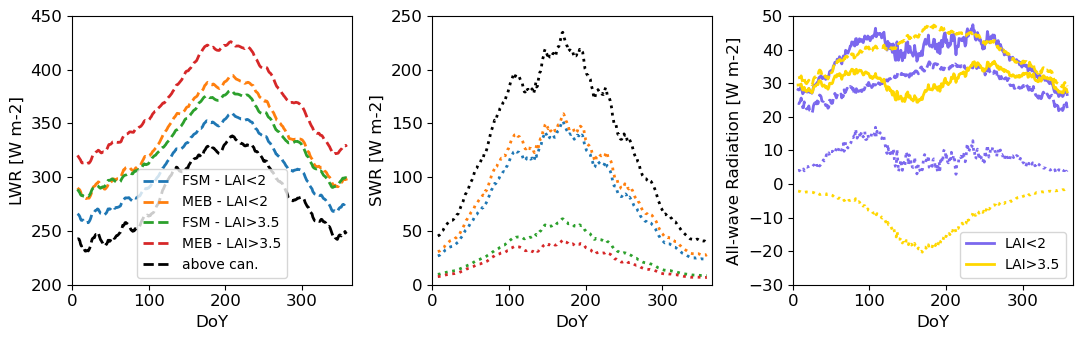

In [20]:
class_names = list(fsm_classes.keys())


# --- Create subplots ---
fig, axs = plt.subplots(1,3, figsize=(11.5, 3.5), sharex=True)

# --- Loop over each LAI class ---
for i, class_name in enumerate(class_names):
    fsm_class = fsm_classes[class_name]
    meb_class = meb_classes[class_name]

    q50lw_opn = fsm_class['lwsc_opn'].mean(dim=['yy', 'xx'], skipna=True)   
    q50lw_fsm = fsm_class['lwsc_for'].mean(dim=['yy', 'xx'], skipna=True)
    q50lw_meb = meb_class['LW'].mean(dim=['yy', 'xx'], skipna=True)

    q50sw_opn = fsm_class['swsc_opn'].mean(dim=['yy', 'xx'], skipna=True)
    q50sw_fsm = fsm_class['swsc_for'].mean(dim=['yy', 'xx'], skipna=True)
    q50sw_meb = meb_class['SW'].mean(dim=['yy', 'xx'], skipna=True)

    noleap_lw_opn = q50lw_opn.sel(time=~((q50lw_opn.time.dt.month == 2) & (q50lw_opn.time.dt.day == 29)))
    climlw_opn = noleap_lw_opn.groupby("time.dayofyear").mean("time")
    noleap_lw_fsm = q50lw_fsm.sel(time=~((q50lw_fsm.time.dt.month == 2) & (q50lw_fsm.time.dt.day == 29)))
    climlw_fsm = noleap_lw_fsm.groupby("time.dayofyear").mean("time")
    noleap_lw_meb = q50lw_meb.sel(time=~((q50lw_meb.time.dt.month == 2) & (q50lw_meb.time.dt.day == 29)))
    climlw_meb = noleap_lw_meb.groupby("time.dayofyear").mean("time")

    noleap_sw_opn = q50sw_opn.sel(time=~((q50sw_opn.time.dt.month == 2) & (q50sw_opn.time.dt.day == 29)))
    climsw_opn = noleap_sw_opn.groupby("time.dayofyear").mean("time")
    noleap_sw_fsm = q50sw_fsm.sel(time=~((q50sw_fsm.time.dt.month == 2) & (q50sw_fsm.time.dt.day == 29)))
    climsw_fsm = noleap_sw_fsm.groupby("time.dayofyear").mean("time")
    noleap_sw_meb = q50sw_meb.sel(time=~((q50sw_meb.time.dt.month == 2) & (q50sw_meb.time.dt.day == 29)))
    climsw_meb = noleap_sw_meb.groupby("time.dayofyear").mean("time")

    sw_diff = noleap_sw_meb-noleap_sw_fsm
    climsw_diff = sw_diff.groupby("time.dayofyear").mean("time")

    lw_diff = noleap_lw_meb-noleap_lw_fsm
    climlw_diff = lw_diff.groupby("time.dayofyear").mean("time")

    time_fsm = q50lw_fsm['time'].values
    time_meb = q50lw_meb['time'].values

    ax = axs[0]
    ax.plot(climlw_fsm.rolling(dayofyear=15, center=True).mean(), color=color_fsm[i], linewidth=2, linestyle='dashed', label=label_fsm[i])
    ax.plot(climlw_meb.rolling(dayofyear=15, center=True).mean(), color=color_meb[i], linewidth=2, linestyle='dashed', label=label_meb[i])
    if i == 1 :
        ax.plot(climlw_opn.rolling(dayofyear=15, center=True).mean(), color='black', linewidth=2, linestyle='dashed', label='above can.')

    ax = axs[1]
    ax.plot(climsw_fsm.rolling(dayofyear=15, center=True).mean(), color=color_fsm[i], linewidth=2, linestyle='dotted', label=label_fsm[i])
    ax.plot(climsw_meb.rolling(dayofyear=15, center=True).mean(), color=color_meb[i], linewidth=2, linestyle='dotted', label=label_meb[i])

    if i == 1 :
        ax.plot(climsw_opn.rolling(dayofyear=15, center=True).mean(), color='black', linewidth=2, linestyle='dotted', label='above can.')


    climsw_smooth = climsw_diff.rolling(dayofyear=15, center=True).mean()
    climlw_smooth = climlw_diff.rolling(dayofyear=15, center=True).mean()
    ax = axs[2]
   
    ax.plot(climsw_smooth, color=color_diff[i], linewidth=2, linestyle='dotted')
    ax.plot(climlw_smooth, color=color_diff[i], linewidth=2, linestyle='dashed')
    ax.plot(climsw_smooth+climlw_smooth, color=color_diff[i], linewidth=2, label=label_dif[i])
    

ax = axs[0]
ax.legend()
ax.set_ylim(200,450)
ax.set_ylabel('LWR [W m-2]', fontsize=12)

ax = axs[1]
ax.set_ylim(0,250)
ax.set_ylabel('SWR [W m-2]', fontsize=12)
#ax.legend()

ax = axs[2]
ax.set_ylim(-30,50)
ax.set_ylabel('All-wave Radiation [W m-2]', fontsize=12)
ax.legend()

for i in np.arange(3) :
    axs[i].tick_params(labelsize=12)
    axs[i].set_xlabel('DoY', fontsize=12)
    axs[i].set_xlim(0,365)

plt.tight_layout(rect=[0.05, 0, 1, 1])
# plt.savefig(f'figs/lw_ts_lai_classes.png', dpi=300, bbox_inches='tight')